In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
import numpy as np
from sklearn.decomposition import PCA
from scipy.stats import chi2_contingency
import numpy as np
import os
from tqdm import tqdm

In [2]:
pd.set_option('display.max_columns', None)
plt.rcParams['svg.fonttype'] = 'none'

## Look into population distribution of centromeres using the 1kGP and HGDP projects

In [3]:
chromosomes=["chr1", "chr2", "chr3", "chr4", "chr5", "chr6", "chr7", "chr8", "chr9", "chr10", "chr11", "chr12", "chr16", "chr17", "chr18", "chr19", "chr20"]

#### Load 1kGP and HGDP predictions

In [4]:
df = pd.read_csv("complete_population_predictions.tsv", sep="\t")
df = df[df["PROJECT"].isin(["1kGP", "HGDP"])].copy().reset_index(drop=True)

In [5]:
df["PRED_VALUES"] = df["PRED_VALUES"].apply(
    lambda value: np.fromstring(value.strip("[]"), sep=" ").tolist()
)

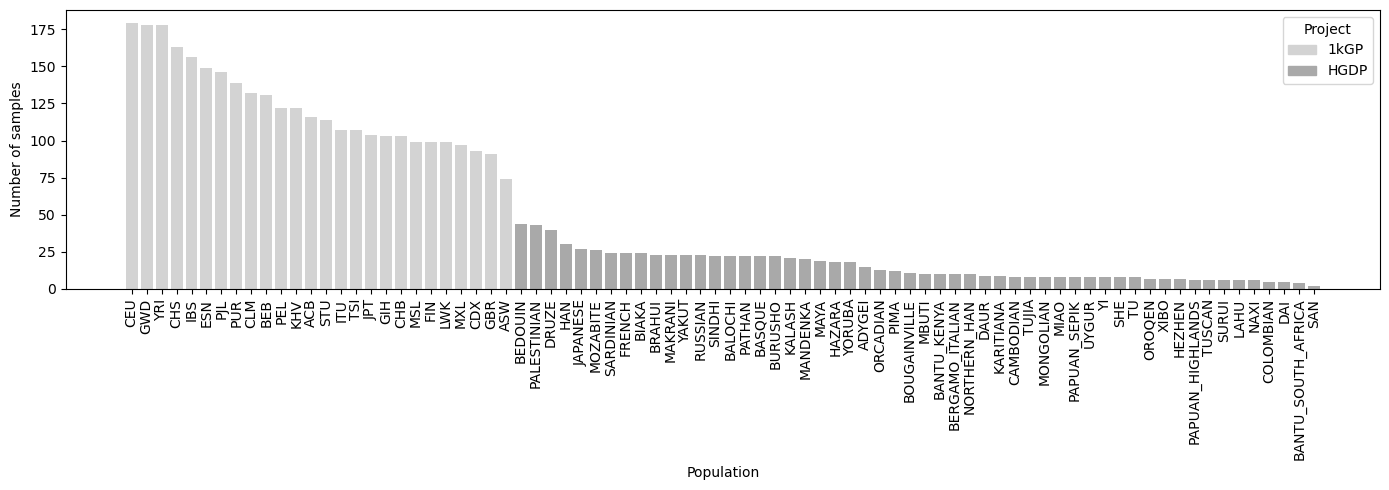

In [6]:
population_counts = (
    df.groupby(["POPULATION", "PROJECT"], as_index=False)["SAMPLE"]
    .nunique()
    .rename(columns={"SAMPLE": "N_SAMPLES"}) # type: ignore
    .sort_values("N_SAMPLES", ascending=False)
 )

project_colors = {"1kGP": "lightgray", "HGDP": "darkgray"}

fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(
    population_counts["POPULATION"],
    population_counts["N_SAMPLES"],
    color=population_counts["PROJECT"].map(project_colors),
 )
ax.set_xlabel("Population")
ax.set_ylabel("Number of samples")
ax.tick_params(axis="x", rotation=90)
ax.legend(
    handles=[Patch(color=color, label=project) for project, color in project_colors.items()],
    title="Project",
 )
plt.tight_layout()
plt.show()

## Load population metadata

In [7]:
translate = {
    "EAST ASIA (SGDP)":"EAS",
    "EAST ASIA (HGDP)":"EAS",
    "AFRICA (SGDP)":"AFR",
    "AFRICA (HGDP)":"AFR",
    "AMERICA (SGDP)":"AMR",
    "AMERICA (HGDP)":"AMR",
    "EUROPE (HGDP)":"EUR",
    "MIDDLE EAST (HGDP)":"MEE",
    "OCEANIA (HGDP)":"OCE",
    "OCEANIA (SGDP)":"OCE",
    "CENTRAL SOUTH ASIA (HGDP)":"CSA",
    "CENTRAL ASIA AND SIBERIA (SGDP)":"CSA",
    "WEST EURASIA (SGDP)":"CSA",
    "SOUTH ASIA (SGDP)":"CSA"
}

In [8]:
superpopulations = ["AFR", "AMR", "EAS", "EUR", "SAS", "CSA", "MEE", "OCE"]
superpopulation_colors = ["#FFCD33", "#FF3D3D", "#ADFF33", "#64EBFF", "#FF30FF", "#2ea836", "thistle", "#1c65ff"]

project_to_color = {"HGDP":"darkgray", "1kGP":"lightgray"}

superpop_to_color = {}
for pop, c in zip(superpopulations, superpopulation_colors):
    superpop_to_color[pop] = c

In [9]:
pop_location_df_data = {"POP":[], "LAT":[], "LON":[], "SPOP":[], "COLOR":[], "PRJ":[]} #

for line in open("igsr_populations.tsv"):
    if line.startswith("Population code"):
        pass
    else:
        pop = line.strip().split("\t")[1].upper()
        lat = float(line.split("\t")[4])
        lon = float(line.split("\t")[5])
        spop = line.strip().split("\t")[6].upper()
        
        prj = "KGP"
        if "Human Genome Diversity Project" in line:
            prj = "HGDP"

        if not ("SGDP" in spop) and spop.strip() != "":

            pop_location_df_data["POP"].append(pop)
            pop_location_df_data["LAT"].append(lat)
            pop_location_df_data["LON"].append(lon)
            pop_location_df_data["PRJ"].append(prj)
            if spop in translate:
                pop_location_df_data["SPOP"].append(translate[spop])
                pop_location_df_data["COLOR"].append(superpop_to_color[translate[spop]])
            else:
                pop_location_df_data["SPOP"].append(spop)
                pop_location_df_data["COLOR"].append(superpop_to_color[spop])

pop_location_df = pd.DataFrame(pop_location_df_data)

In [10]:
spop_order = ["AFR", "AMR", "EAS", "EUR", "SAS", "CSA", "OCE", "MEE"]
spop_color = []
for spop in spop_order:
    spop_color.append(pop_location_df[pop_location_df["SPOP"] == spop]["COLOR"].values[0])

## Analysis

#### Shannon entropy

In [11]:
def calculate_normalized_shannon_entropy(data, group_column):
    """Calculate normalized architecture entropy and allele frequencies by chromosome and group."""
    required_columns = {"CHROM", group_column, "CLUSTER_H1", "CLUSTER_H2"}
    missing_columns = required_columns.difference(data.columns)
    if missing_columns:
        raise ValueError(f"Missing required columns: {sorted(missing_columns)}")

    entropy_rows = []
    allele_frequency_data = {}

    for chrom, chrom_data in data.groupby("CHROM"):
        called_data = chrom_data.dropna(subset=["CLUSTER_H1", "CLUSTER_H2"])
        clusters = np.sort(called_data[["CLUSTER_H1", "CLUSTER_H2"]].to_numpy().ravel())
        clusters = pd.unique(clusters)
    
        allele_calls = called_data.melt(
            id_vars=group_column,
            value_vars=["CLUSTER_H1", "CLUSTER_H2"],
            value_name="COL_CLUSTER",
        )
        allele_counts = (
            allele_calls.groupby(["COL_CLUSTER", group_column])
            .size()
            .unstack(group_column, fill_value=0)
            .reindex(clusters, fill_value=0)
        )
        allele_frequencies = allele_counts.divide(allele_counts.sum(axis=0), axis=1)
        allele_frequency_data[chrom] = allele_frequencies

        for group, frequencies in allele_frequencies.items():
            nonzero_frequencies = frequencies[frequencies > 0]
            entropy = -np.sum(nonzero_frequencies * np.log(nonzero_frequencies))
            normalized_entropy = entropy / np.log(len(clusters)) if len(clusters) > 1 else np.nan

            row = {
                "CHROM": chrom,
                group_column: group,
                "H": normalized_entropy,
                "N_CLUSTER": len(clusters),
                "N_SAMPLES": allele_counts[group].sum() / 2,
            }
            if group_column == "POPULATION":
                row["SUPERPOPULATION"] = chrom_data.loc[
                    chrom_data[group_column] == group, "SUPERPOPULATION"
                ].iloc[0]
            entropy_rows.append(row)
            
    return pd.DataFrame(entropy_rows)

In [12]:
superpopulation_shannon_df = calculate_normalized_shannon_entropy(df, "SUPERPOPULATION")
population_shannon_df = calculate_normalized_shannon_entropy(df, "POPULATION")

In [13]:
superpopulation_shannon_df = superpopulation_shannon_df[
    (superpopulation_shannon_df["N_CLUSTER"] >= 3) &
    (superpopulation_shannon_df["N_SAMPLES"] >= 5)
].copy().reset_index(drop=True)

population_shannon_df = population_shannon_df[
    (population_shannon_df["N_CLUSTER"] >= 3) &
    (population_shannon_df["N_SAMPLES"] >= 5)
].copy().reset_index(drop=True)

#### Figure 3B - Shannon

/tmp/ipykernel_1822155/111805231.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


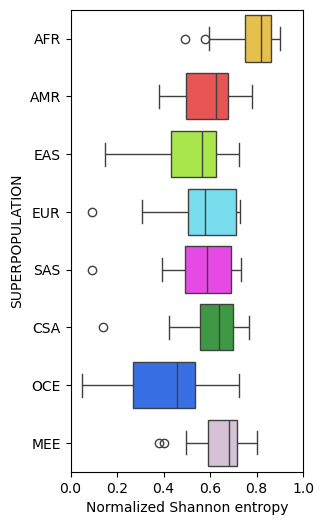

In [ ]:
fig, ax = plt.subplots(figsize=(4, 4))
sns.boxplot(
    superpopulation_shannon_df,
    y="SUPERPOPULATION",
    x="H",
    ax=ax,
    order=spop_order,
    palette=spop_color
)
ax.set_xlim(0, 1)
ax.set_xlabel("Normalized Shannon entropy")
plt.gcf().set_size_inches((3, 6))
plt.savefig("../plotting/plots/population_superpopulation_shannon_boxplot.svg")
plt.show()

/tmp/ipykernel_1822155/1377798707.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


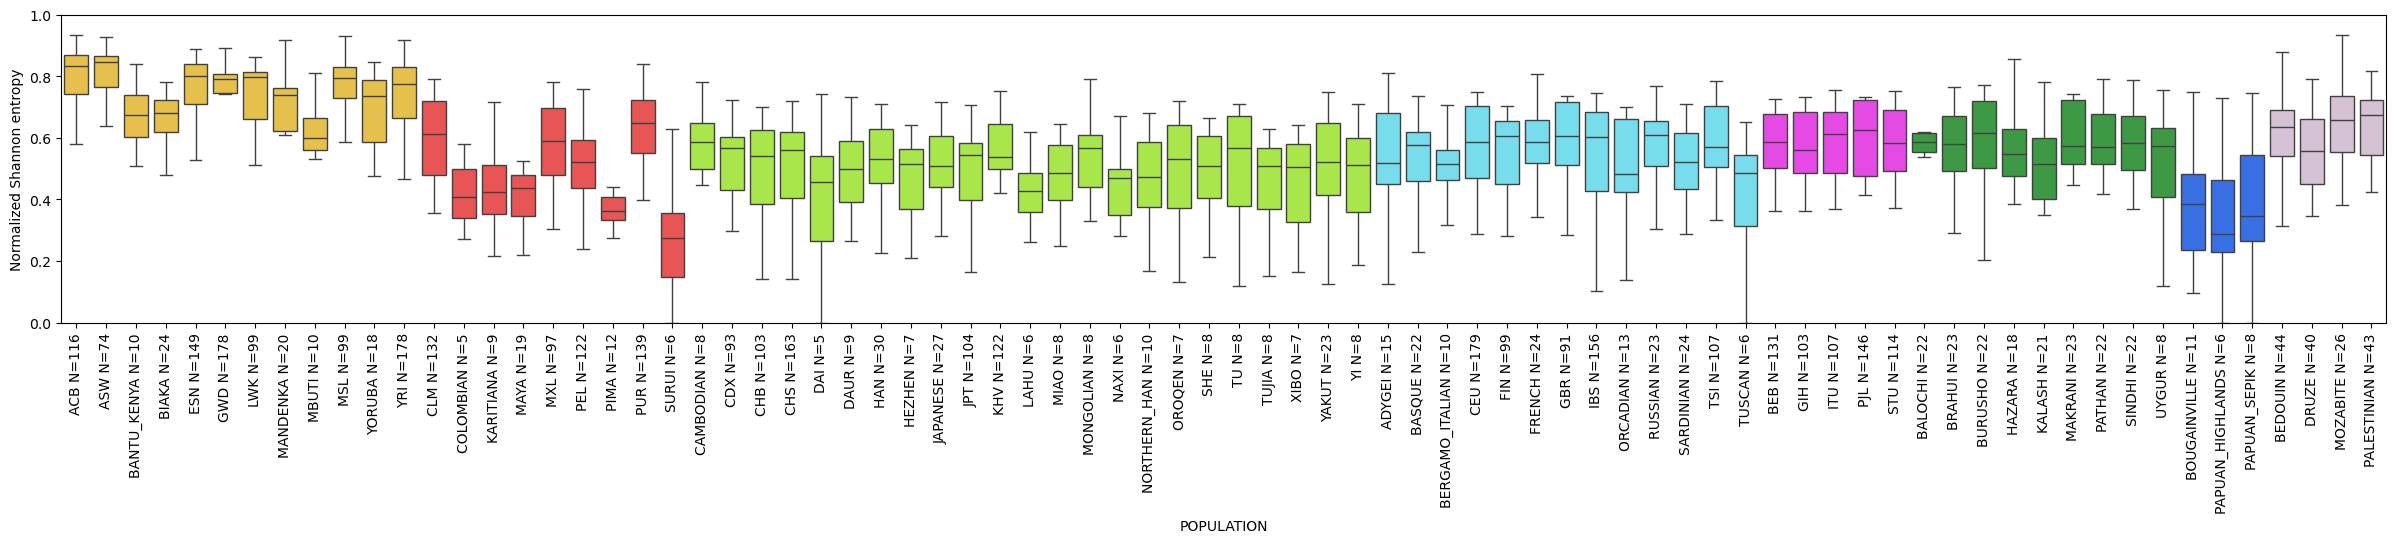

In [15]:
pop_order = []
for spop in spop_order:
    pop_order += sorted(population_shannon_df[population_shannon_df["SUPERPOPULATION"] == spop]["POPULATION"].unique())
pop_color = []
for p in pop_order:
    if pop_location_df[pop_location_df["POP"] == p].shape[0] != 1:
        spop = population_shannon_df[population_shannon_df["POPULATION"] == p]["SUPERPOPULATION"].values[0]
        pop_color.append(pop_location_df[pop_location_df["SPOP"] == spop]["COLOR"].values[0])
    else:
        pop_color.append(pop_location_df[pop_location_df["POP"] == p]["COLOR"].values[0])
pop_N = []
for p in pop_order:
    pop_N.append(df[df["POPULATION"] == p]["SAMPLE"].nunique())

fig, ax = plt.subplots(figsize=(30, 4))
sns.boxplot(
    population_shannon_df,
    x="POPULATION",
    y="H",
    ax=ax,
    order=pop_order,
    fliersize=0,
    palette=pop_color
)
ax.set_ylim(0, 1)

labels = [f"{pop_order[i]} N={int(pop_N[i])}" for i in range(len(pop_order))]
ax.set_xticks(range(len(pop_order)), labels)

plt.xticks(rotation=90)
ax.set_ylabel("Normalized Shannon entropy")
plt.show()

In [16]:
import plotly.express as px
import pandas as pd

fig = px.scatter_geo(pop_location_df,
                     lat='LAT',
                     lon='LON',
                     projection='natural earth')

# Apply custom color per point
fig.update_traces(marker=dict(size=8, color=pop_location_df['COLOR'], line=dict(width=0)))

# Remove point hover labels
fig.update_traces(hoverinfo='skip')

fig.update_layout(title='Custom Colored Points on World Map')
fig.show()


#### Scatter of centromere shannon vs SNP shannon

In [17]:
dfs = []
for chrom in [f"chr{x}" for x in range(1, 23)]:
    if not os.path.exists(f"/scratch/hain/pop_freq/{chrom}_het.tsv"):
        continue
    snp_df = pd.read_csv(f"/scratch/hain/pop_freq/{chrom}_het.tsv", sep="\t").set_index("POPULATION")
    dfs.append(snp_df)
snp_df = pd.concat(dfs, axis=1)
snp_mean = snp_df.mean(axis=1)

Error processing population BOUGAINVILLE: 'bougainville'


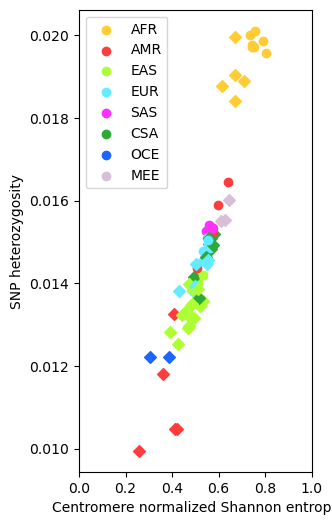

In [ ]:
fig, ax = plt.subplots()
#ax.set_title("Centromere normalized Shannon entropy\nvs.\nSNP heterozygosity")
ax.set_xlabel("Centromere normalized Shannon entropy")
ax.set_ylabel("SNP heterozygosity")

x_spear = []
y_spear = []

for pop in population_shannon_df["POPULATION"].unique():
    pop_lower = pop.lower()
    
    try:
        cent_shannon = population_shannon_df.loc[population_shannon_df["POPULATION"] == pop, "H"].mean()
        cent_shannon_std = population_shannon_df.loc[population_shannon_df["POPULATION"] == pop, "H"].std()
        if "papua" in pop_lower:
            snp = snp_mean.loc["papuan"]
        elif "biaka" in pop_lower:
            snp = snp_mean.loc["biakapygmy"]
        elif "mbuti" in pop_lower:
            snp = snp_mean.loc["mbutipygmy"]
        elif "bantu_kenya" in pop_lower:
            snp = snp_mean.loc["bantukenya"]
        elif "bergamo_italian" in pop_lower:
            snp = snp_mean.loc["italian"]
        elif "mongolian" in pop_lower:
            snp = snp_mean.loc["mongola"]
        elif "yi" in pop_lower:
            snp = snp_mean.loc["yizu"]
        elif "northern_han" in pop_lower:
            snp = snp_mean.loc["han"]
        elif "miao" in pop_lower:
            snp = snp_mean.loc["miaozu"]
        else:
            snp = snp_mean.loc[pop_lower]
        color = pop_location_df.loc[pop_location_df["POP"] == pop.replace("_", " "), "COLOR"].values[0]
        if pop_location_df.loc[pop_location_df["POP"] == pop.replace("_", " "), "PRJ"].values[0] == "KGP":
            marker = "o"
        else:
            marker = "D"
        
        
        #ax.errorbar(cent_shannon, snp, xerr=cent_shannon_std, fmt='o', label=pop, color=color)
        ax.scatter(cent_shannon, snp, color=color, marker=marker)
        x_spear.append(cent_shannon)
        y_spear.append(snp)
        
        #print(f"Population: {pop}, Centromere Shannon: {cent_shannon}, SNP Shannon: {snp_shannon}")
    except Exception as e:
        print(f"Error processing population {pop}: {e}")

xlim = ax.get_xlim()
ylim = ax.get_ylim()

for pop in ["AFR", "AMR", "EAS", "EUR", "SAS", "CSA", "OCE", "MEE"]:
    ax.scatter(-10, -10, label=pop, color=superpop_to_color[pop])
        
ax.set_xlim(xlim)
ax.set_ylim(ylim)
ax.legend()
ax.set_xlim(0, 1)

plt.gcf().set_size_inches(3, 6)

plt.savefig("../plotting/plots/population_centromere_vs_snp_heterozygosity.png")
plt.savefig("../plotting/plots/population_centromere_vs_snp_heterozygosity.svg")
plt.show()

In [19]:
from scipy.stats import spearmanr

rho, p = spearmanr(
    x_spear,
    y_spear
)

print(f"Spearman rho = {rho:.3f}, p = {p:.2e}")

Spearman rho = 0.958, p = 1.29e-42


In [20]:
col_snp_shannon = []
col_n = []

for _, row in pop_location_df.iterrows():
    
    try:
        col_n.append(population_counts[population_counts["POPULATION"] == row["POP"]]["N_SAMPLES"].values[0])
    except Exception as e:
        col_n.append(pd.NA)
    
    try:
        pop_lower = row["POP"].lower().replace(" ", "_")
        #print(pop_lower)
        snp_shannon = snp_shannon_df.loc[snp_shannon_df["POPULATION"] == pop_lower, "mean_site_shannon_entropy"].values[0]
        col_snp_shannon.append(snp_shannon)
    except Exception as e:
        col_snp_shannon.append(pd.NA)
pop_location_df["snp_shannon"] = col_snp_shannon
pop_location_df["n"] = col_n

## Missingness analysis

In [22]:
col_error = []
for _, row in df.iterrows():
    pred_values = row["PRED_VALUES"]
    n_call = (np.array(row["PRED_VALUES"]) >= 0.5).sum()
    if n_call == 0:
        col_error.append("MISS")
    elif n_call > 2:
        col_error.append("MANY")
    elif n_call == 2:
        col_error.append("HET")
    elif n_call == 1:
        col_error.append("HOM")
df["ERROR"] = col_error

In [23]:
data = []
for pop, pop_df in df.groupby("POPULATION"):
    missing = pop_df[
        pop_df["ERROR"] == "MISS"
    ].shape[0]
    many = pop_df[
        pop_df["ERROR"] == "MANY"
    ].shape[0]
    het = pop_df[
        pop_df["ERROR"] == "HET"
    ].shape[0]
    hom = pop_df[
        pop_df["ERROR"] == "HOM"
    ].shape[0]
    total = pop_df.shape[0]
    n_samples = pop_df["SAMPLE"].nunique()
    data.append({"POP":pop, "N_CHROM":total, "N_SAMPLE":n_samples, "FRAC_MISS":missing / total, "FRAC_MANY":many / total, "FRAC_HET":het / total, "FRAC_HOM":hom / total})

In [24]:
pd.DataFrame(data).sort_values(by="FRAC_MISS").tail(10)

,POP,N_CHROM,N_SAMPLE,FRAC_MISS,FRAC_MANY,FRAC_HET,FRAC_HOM
72,TUJIA,136,8,0.007353,0.000000,0.566176,0.426471
57,PAPUAN_SEPIK,136,8,0.007353,0.000000,0.404412,0.588235
42,MAKRANI,391,23,0.007673,0.000000,0.514066,0.478261
24,ESN,2533,149,0.008291,0.017371,0.594947,0.379392
8,BEDOUIN,748,44,0.009358,0.014706,0.533422,0.442513
20,COLOMBIAN,85,5,0.011765,0.011765,0.529412,0.447059
5,BANTU_SOUTH_AFRICA,68,4,0.029412,0.014706,0.470588,0.485294
10,BIAKA,408,24,0.066176,0.014706,0.404412,0.514706
64,SAN,34,2,0.117647,0.000000,0.382353,0.500000
45,MBUTI,170,10,0.123529,0.005882,0.382353,0.488235


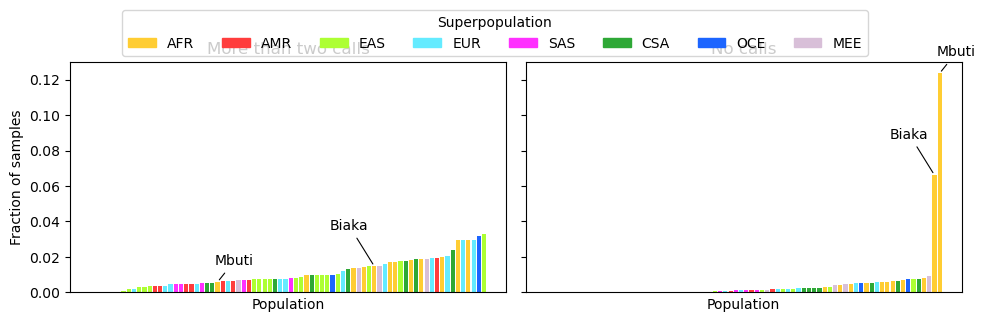

In [25]:
population_superpopulations = df[["POPULATION", "SUPERPOPULATION"]].drop_duplicates()
missingness_df = (
    pd.DataFrame(data)
    .merge(
        population_superpopulations,
        left_on="POP",
        right_on="POPULATION",
        validate="one_to_one",
    )
    .query("N_SAMPLE >= 6")
 )
max_fraction = missingness_df[["FRAC_MANY", "FRAC_MISS"]].to_numpy().max()
annotation_offsets = {"BIAKA": (-18, 24), "MBUTI": (12, 10)}

fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
for ax, fraction, title in zip(
    axes,
    ["FRAC_MANY", "FRAC_MISS"],
    ["More than two calls", "No calls"],
):
    plot_df = missingness_df.sort_values(fraction, ascending=True).reset_index(drop=True)
    bar_colors = plot_df["SUPERPOPULATION"].map(superpop_to_color)
    x_positions = np.arange(len(plot_df))

    ax.bar(x_positions, plot_df[fraction], color=bar_colors)
    for population, offset in annotation_offsets.items():
        population_row = plot_df[plot_df["POP"] == population]
        if not population_row.empty:
            x_position = population_row.index[0]
            value = population_row[fraction].iloc[0]
            ax.annotate(
                population.title(),
                xy=(x_position, value),
                xytext=offset,
                textcoords="offset points",
                ha="center",
                va="bottom",
                arrowprops={"arrowstyle": "-", "linewidth": 0.8},
            )

    ax.set_title(title)
    ax.set_xlabel(f"Population")
    ax.set_xticks([])
    ax.set_ylim(0, max_fraction * 1.05 if max_fraction > 0 else 1)

axes[0].set_ylabel("Fraction of samples")
fig.legend(
    handles=[
        Patch(color=superpop_to_color[superpopulation], label=superpopulation)
        for superpopulation in spop_order
    ],
    title="Superpopulation",
    loc="upper center",
    ncols=len(spop_order),
    bbox_to_anchor=(0.5, 1.08),
)
plt.tight_layout()
plt.show()

### Do the same on a superpopulation level

In [26]:
data_miss_spop = []
for pop, pop_df in df.groupby("SUPERPOPULATION"):
    for chrom, chrom_pop_df in pop_df.groupby("CHROM"):
        missing = chrom_pop_df[
            chrom_pop_df["ERROR"] == "MISS"
        ].shape[0]
        many = chrom_pop_df[
            chrom_pop_df["ERROR"] == "MANY"
        ].shape[0]
        het = chrom_pop_df[
            chrom_pop_df["ERROR"] == "HET"
        ].shape[0]
        hom = chrom_pop_df[
            chrom_pop_df["ERROR"] == "HOM"
        ].shape[0]
        total = chrom_pop_df.shape[0]
        n_samples = chrom_pop_df["SAMPLE"].nunique()
        data_miss_spop.append({
            "POP":pop, 
            "CHROM":chrom, 
            "N_CHROM":total, 
            "N_SAMPLE":n_samples, 
            "FRAC_MISS":missing / total, 
            "FRAC_MANY":many / total, 
            "FRAC_HET":het / total, 
            "FRAC_HOM":hom / total})

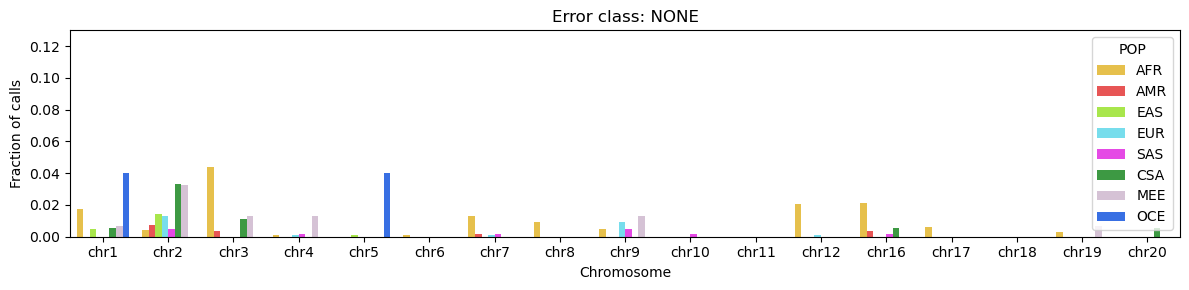

In [ ]:
fig, ax = plt.subplots(figsize=(12, 3))
sns.barplot(
    pd.DataFrame(data_miss_spop), 
    x="CHROM", y="FRAC_MISS", hue="POP", 
    palette=list(superpop_to_color.values()),
    hue_order=list(superpop_to_color.keys()),
    order=chromosomes
    )
ax.set_ylabel("Fraction of calls")
ax.set_xlabel("Chromosome")
ax.set_title("Error class: NONE")
ax.set_ylim(0, 0.13)

plt.tight_layout()
plt.savefig("../plotting/plots/population_S_MISSINGNESS_SUPERPOPULATION_PER_CHROMOSOME.png")

### MFA

In [66]:
import prince

In [90]:
print(prince.__version__)

0.14.0


In [67]:
### calculate af per cluster per population
populations = df["POPULATION"].unique()
clusters = [x for x in list(set(df["CLUSTER_H1"].tolist() + df["CLUSTER_H2"].tolist())) if not pd.isna(x)]
af_df = pd.DataFrame(index=sorted(populations), columns=clusters).fillna(0)

/tmp/ipykernel_1822155/3615856436.py:4: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  af_df = pd.DataFrame(index=sorted(populations), columns=clusters).fillna(0)


In [68]:
h1 = pd.crosstab(df["POPULATION"], df["CLUSTER_H1"])
h2 = pd.crosstab(df["POPULATION"], df["CLUSTER_H2"])
### fix for na
h2["chr19_912"] = 0

for population in populations:
    for cluster in clusters:
        n_cluster = h1.loc[population, cluster] + h2.loc[population, cluster]
        chrom = cluster.split("_")[0]
        n_chrom = h1.loc[population, h1.columns[h1.columns.str.startswith(f"{chrom}_")]].sum() + h2.loc[population, h2.columns[h2.columns.str.startswith(f"{chrom}_")]].sum()
        
        if pd.isna(n_cluster) or pd.isna(n_chrom) or n_chrom == 0: # type: ignore
            continue
        
        af_df.loc[population, cluster] = n_cluster / n_chrom

/tmp/ipykernel_1822155/1828156675.py:15: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.1043956043956044' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  af_df.loc[population, cluster] = n_cluster / n_chrom
/tmp/ipykernel_1822155/1828156675.py:15: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.038461538461538464' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  af_df.loc[population, cluster] = n_cluster / n_chrom
/tmp/ipykernel_1822155/1828156675.py:15: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.38953488372093026' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  af_df.loc[population, cluster] = n_cluster / n_chrom
/

In [69]:
df_mfa = af_df.fillna(0).astype(float).copy()

In [83]:
df.drop_duplicates(subset=["SAMPLE", "POPULATION"])["POPULATION"].value_counts()

POPULATION
CEU                   179
GWD                   178
YRI                   178
CHS                   163
IBS                   156
                     ... 
SURUI                   6
COLOMBIAN               5
DAI                     5
BANTU_SOUTH_AFRICA      4
SAN                     2
Name: count, Length: 80, dtype: int64

In [88]:
### remove populations with low sample count
small_populations = ["BANTU_SOUTH_AFRICA", "SAN"]
df_mfa = df_mfa.loc[~df_mfa.index.isin(small_populations)]

In [89]:
groups = {}
for cluster in df_mfa.columns:
    chrom = cluster.split("_")[0]
    groups.setdefault(chrom, []).append(cluster)

mfa = prince.MFA(
    n_components=10,
    n_iter=5,
    copy=True,
    check_input=True,
    engine="sklearn",
    random_state=42,
)

mfa = mfa.fit(df_mfa, groups=groups)

#### Figure 3A - MFA

In [91]:
header_df = pop_location_df.set_index("POP")

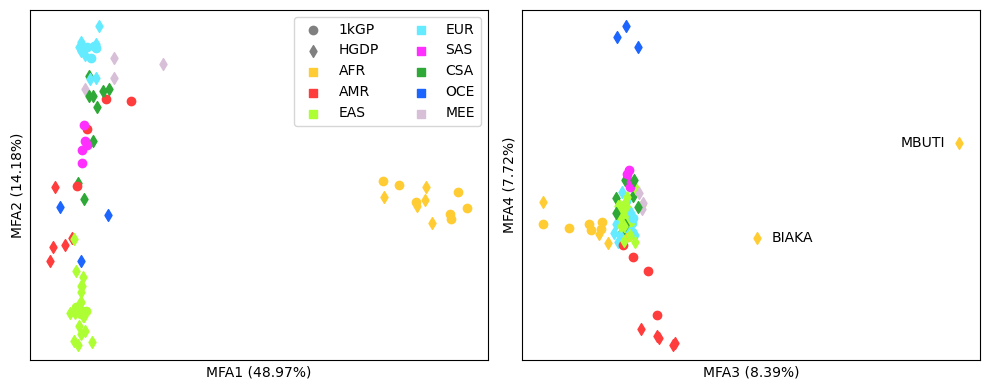

In [92]:
ax_a = plt.subplot(1, 2, 1)
ax_b = plt.subplot(1, 2, 2)

for idx, row in mfa.row_coordinates(df_mfa).iterrows(): # type: ignore

    color = "k"
    shape = "o"
    
    pop_name = idx.replace("_", " ")
    if pop_name in pop_location_df["POP"].values:
        color = pop_location_df[pop_location_df["POP"] == pop_name]['COLOR'].values[0]
        if pop_location_df[pop_location_df["POP"] == pop_name]['PRJ'].values[0] == "HGDP":
            shape = "d"
    else:
        print(idx)


    ax_a.scatter(row[0], row[1], c=color, marker=shape)
    ax_b.scatter(row[2], row[3], c=color, marker=shape)

    if idx == "BIAKA":
        ax_b.text(row[2] + .5, row[3], s=idx, ha="left", va="center")
    if idx == "MBUTI":
        ax_b.text(row[2] - .5, row[3], s=idx, ha="right", va="center")
    
ax_a.set_xlabel(f"MFA1 ({mfa.eigenvalues_summary.loc[0]["% of variance"]})")
ax_a.set_ylabel(f"MFA2 ({mfa.eigenvalues_summary.loc[1]["% of variance"]})")

ax_b.set_xlabel(f"MFA3 ({mfa.eigenvalues_summary.loc[2]["% of variance"]})")
ax_b.set_ylabel(f"MFA4 ({mfa.eigenvalues_summary.loc[3]["% of variance"]})")

x_min, x_max = ax_a.get_xlim()
y_min, y_max = ax_a.get_ylim()


ax_a.scatter(-100, -100, c="gray", marker="o", label="1kGP")
ax_a.scatter(-100, -100, c="gray", marker="d", label="HGDP")
ax_a.scatter(-100, -100, c=header_df.loc["YRI"]['COLOR'], marker="s", label="AFR")
ax_a.scatter(-100, -100, c=header_df.loc["PEL"]['COLOR'], marker="s", label="AMR")
ax_a.scatter(-100, -100, c=header_df.loc["HAN"]['COLOR'], marker="s", label="EAS")
ax_a.scatter(-100, -100, c=header_df.loc["GBR"]['COLOR'], marker="s", label="EUR")
ax_a.scatter(-100, -100, c=header_df.loc["BEB"]['COLOR'], marker="s", label="SAS")

ax_a.scatter(-100, -100, c=header_df.loc["BALOCHI"]['COLOR'], marker="s", label="CSA")
ax_a.scatter(-100, -100, c=header_df.loc["BOUGAINVILLE"]['COLOR'], marker="s", label="OCE")
ax_a.scatter(-100, -100, c=header_df.loc["MOZABITE"]['COLOR'], marker="s", label="MEE")




ax_a.legend(ncols=2)

ax_a.set_xlim(x_min, x_max)
ax_a.set_ylim(y_min, y_max)

ax_a.set_xticks([])
ax_a.set_yticks([])
ax_b.set_xticks([])
ax_b.set_yticks([])

plt.gcf().set_size_inches((10, 4))
plt.tight_layout()
plt.show()

#### Figure 3 - complete

In [93]:
import matplotlib as mpl
mpl.rcParams['svg.fonttype'] = 'none'

In [94]:
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

/tmp/ipykernel_1822155/559022706.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


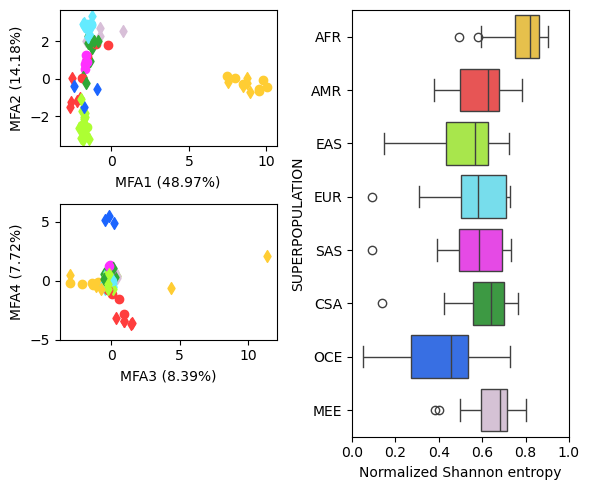

In [ ]:

fig = plt.figure(figsize=(6, 5))
gs = GridSpec(5, 2, figure=fig)

ax_mfa_1 = fig.add_subplot(gs[0:2, 0])
ax_mfa_2 = fig.add_subplot(gs[2:4, 0])
ax_shannon = fig.add_subplot(gs[:, 1])

######### MFA plot

for idx, row in mfa.row_coordinates(df_mfa).iterrows(): # type: ignore

    color = "k"
    shape = "o"
    
    pop_name = idx.replace("_", " ")
    if pop_name in pop_location_df["POP"].values:
        color = pop_location_df[pop_location_df["POP"] == pop_name]['COLOR'].values[0]
        if pop_location_df[pop_location_df["POP"] == pop_name]['PRJ'].values[0] == "HGDP":
            shape = "d"
    else:
        print(idx)
        

    ax_mfa_1.scatter(row[0], row[1], c=color, marker=shape)

    ax_mfa_2.scatter(row[2], row[3], c=color, marker=shape)

x_min, x_max = ax_mfa_1.get_xlim()
y_min, y_max = ax_mfa_1.get_ylim()

ax_a.scatter(-100, -100, c="gray", marker="o", label="1kGP")
ax_a.scatter(-100, -100, c="gray", marker="d", label="HGDP")
ax_a.scatter(-100, -100, c=header_df.loc["YRI"]['COLOR'], marker="s", label="AFR")
ax_a.scatter(-100, -100, c=header_df.loc["PEL"]['COLOR'], marker="s", label="AMR")
ax_a.scatter(-100, -100, c=header_df.loc["HAN"]['COLOR'], marker="s", label="EAS")
ax_a.scatter(-100, -100, c=header_df.loc["GBR"]['COLOR'], marker="s", label="EUR")
ax_a.scatter(-100, -100, c=header_df.loc["BEB"]['COLOR'], marker="s", label="SAS")

ax_a.scatter(-100, -100, c=header_df.loc["BALOCHI"]['COLOR'], marker="s", label="CSA")
ax_a.scatter(-100, -100, c=header_df.loc["BOUGAINVILLE"]['COLOR'], marker="s", label="OCE")
ax_a.scatter(-100, -100, c=header_df.loc["MOZABITE"]['COLOR'], marker="s", label="MEE")

#ax_mfa_1.legend(ncols=4)

ax_mfa_1.set_xlim(x_min, x_max)
ax_mfa_1.set_ylim(y_min, y_max)

ax_mfa_1.set_xlabel(f"MFA1 ({mfa.eigenvalues_summary.loc[0]["% of variance"]})")
ax_mfa_1.set_ylabel(f"MFA2 ({mfa.eigenvalues_summary.loc[1]["% of variance"]})")

ax_mfa_2.set_xlabel(f"MFA3 ({mfa.eigenvalues_summary.loc[2]["% of variance"]})")
ax_mfa_2.set_ylabel(f"MFA4 ({mfa.eigenvalues_summary.loc[3]["% of variance"]})")

### manually set xticks
ax_mfa_1.set_xticks([0, 5, 10])
ax_mfa_2.set_xticks([0, 5, 10])

ax_mfa_1.set_yticks([-2, 0, 2])
ax_mfa_2.set_yticks([-5, 0, 5])
ax_mfa_2.set_ylim(-5, 6.5)

######### Shannon entropy plot
sns.boxplot(
    superpopulation_shannon_df,
    y="SUPERPOPULATION",
    x="H",
    ax=ax_shannon,
    order=spop_order,
    palette=spop_color
)
ax_shannon.set_xlim(0, 1)
ax_shannon.set_xlabel("Normalized Shannon entropy")

plt.tight_layout()
plt.savefig("../plotting/plots/population_figure3_mfa_1_mfa_2_shannon_stacked.svg")
plt.show()